### This script does basic bhv quantifications
#### this script runs DLC and quantifies the gazes
#### this script focuses on the summarizing results pooling all six (five in reality, kanga is shared) animals (three dyads); it can only be run after the "BasicBhvAna_singlecam_wholebodylabels_allsessions_basicEvents"

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn
import scipy
import scipy.stats as st
from sklearn.neighbors import KernelDensity
from sklearn.linear_model import LinearRegression
import string
import warnings
import pickle

import os
import glob
import random
from time import time

from pgmpy.models import BayesianModel
from pgmpy.models import DynamicBayesianNetwork as DBN
from pgmpy.estimators import BayesianEstimator
from pgmpy.estimators import HillClimbSearch,BicScore
from pgmpy.base import DAG
import networkx as nx


### function - get body part location for each pair of cameras

In [2]:
from ana_functions.body_part_locs_eachpair import body_part_locs_eachpair
from ana_functions.body_part_locs_singlecam import body_part_locs_singlecam

### function - align the two cameras

In [3]:
from ana_functions.camera_align import camera_align       

### function - merge the two pairs of cameras

In [4]:
from ana_functions.camera_merge import camera_merge

### function - find social gaze time point

In [5]:
from ana_functions.find_socialgaze_timepoint import find_socialgaze_timepoint
from ana_functions.find_socialgaze_timepoint_singlecam import find_socialgaze_timepoint_singlecam
from ana_functions.find_socialgaze_timepoint_singlecam_wholebody import find_socialgaze_timepoint_singlecam_wholebody

### function - define time point of behavioral events

In [6]:
from ana_functions.bhv_events_timepoint import bhv_events_timepoint
from ana_functions.bhv_events_timepoint_singlecam import bhv_events_timepoint_singlecam

### function - plot behavioral events

In [7]:
from ana_functions.plot_bhv_events import plot_bhv_events
from ana_functions.plot_bhv_events_levertube import plot_bhv_events_levertube
from ana_functions.draw_self_loop import draw_self_loop
import matplotlib.patches as mpatches 
from matplotlib.collections import PatchCollection

### function - plot inter-pull interval

In [8]:
from ana_functions.plot_interpull_interval import plot_interpull_interval

### function - make demo videos with skeleton and inportant vectors

In [9]:
from ana_functions.tracking_video_singlecam_demo import tracking_video_singlecam_demo
from ana_functions.tracking_video_singlecam_wholebody_demo import tracking_video_singlecam_wholebody_demo

### function - interval between all behavioral events

In [10]:
from ana_functions.bhv_events_interval import bhv_events_interval

### function - train the dynamic bayesian network - multi time lag (3 lags)

In [11]:
from ana_functions.train_DBN_multiLag import train_DBN_multiLag
from ana_functions.train_DBN_multiLag import train_DBN_multiLag_create_df_only
from ana_functions.train_DBN_multiLag import train_DBN_multiLag_training_only
from ana_functions.train_DBN_multiLag import graph_to_matrix
from ana_functions.train_DBN_multiLag import get_weighted_dags
from ana_functions.train_DBN_multiLag import get_significant_edges
from ana_functions.train_DBN_multiLag import threshold_edges
from ana_functions.train_DBN_multiLag import Modulation_Index
from ana_functions.EfficientTimeShuffling import EfficientShuffle
from ana_functions.AicScore import AicScore

## Analyze each session

### prepare the basic behavioral data (especially the time stamps for each bhv events)
### separate each session based on trial types (different force levels)

In [12]:
# instead of using gaze angle threshold, use the target rectagon to deside gaze info
# ...need to update
sqr_thres_tubelever = 75 # draw the square around tube and lever
sqr_thres_face = 1.15 # a ratio for defining face boundary
sqr_thres_body = 4 # how many times to enlongate the face box boundry to the body


# get the fps of the analyzed video
fps = 30

# frame number of the demo video
# nframes = 0.5*30 # second*30fps
nframes = 1*30 # second*30fps

# re-analyze the video or not
reanalyze_video = 0
redo_anystep = 0

# only analyze the best (five) sessions for each conditions
do_bestsession = 1
if do_bestsession:
    savefile_sufix = '_bestsessions'
else:
    savefile_sufix = '_allsessions'
    

# force manipulation type
# SR_bothchange: self reward, both forces changed
# CO_bothchange: 1s cooperation, both forces changed
# CO_A1change: 1s cooperation, animal 1 forces changed
# CO_A2change: 1s cooperation, animal 2 forces changed
forceManiTypes = ['SR_bothchange','CO_A1change','CO_A2change']
nforceManiTypes = np.shape(forceManiTypes)[0]

#  
animal1_fixedorders = ['koala', 'dannon', 'dodson']
animal2_fixedorders = ['vermelho', 'kanga', 'kanga' ]

animal1_filenames = ["Koala","Dannon","Dodson"]
animal2_filenames = ["Vermelho","Kanga","Kanga"]

nanimalpairs = np.shape(animal1_fixedorders)[0]


# video tracking results info
animalnames_videotrack = ['dodson','scorch'] # does not really mean dodson and scorch, instead, indicate animal1 and animal2
bodypartnames_videotrack = ['rightTuft','whiteBlaze','leftTuft','rightEye','leftEye','mouth']


# which camera to analyzed
cameraID = 'camera-2'
cameraID_short = 'cam2'


# location of levers and tubes for camera 2
# get this information using DLC animal tracking GUI, the results are stored: 
# /home/ws523/marmoset_tracking_DLCv2/marmoset_tracking_with_lever_tube-weikang-2023-04-13/labeled-data/
considerlevertube = 1
considertubeonly = 0
# # camera 1
# lever_locs_camI = {'dodson':np.array([645,600]),'scorch':np.array([425,435])}
# tube_locs_camI  = {'dodson':np.array([1350,630]),'scorch':np.array([555,345])}
# # camera 2
lever_locs_camI = {'dodson':np.array([1335,715]),'scorch':np.array([550,715])}
tube_locs_camI  = {'dodson':np.array([1550,515]),'scorch':np.array([350,515])}
# # lever_locs_camI = {'dodson':np.array([1335,715]),'scorch':np.array([550,715])}
# # tube_locs_camI  = {'dodson':np.array([1650,490]),'scorch':np.array([250,490])}
# # camera 3
# lever_locs_camI = {'dodson':np.array([1580,440]),'scorch':np.array([1296,540])}
# tube_locs_camI  = {'dodson':np.array([1470,375]),'scorch':np.array([805,475])}


# where to save the summarizing data
data_saved_folder = '/gpfs/radev/pi/nandy/jadi_gibbs_data/VideoTracker_SocialInter/3d_recontruction_analysis_forceManipulation_task_data_saved/'


    

In [13]:
# load data for all animals
summary_all_results = pd.DataFrame(columns=['date','forceContType','self_animal','partner_animal','subblockID',
                                            'self_force','partner_force','trialnum','blocktime',
                                            'succ_rate','interpullintv','pull_IPI','pull_IPI_std',
                                            'gaze_number','pull_number','lever_holdtime',
                                            'lever_holdtime_std','lever_gauge','lever_gauge_std',
                                            'ccf_acrossAnimalsPulls','ccf_withinAnimalpullgaze','ccf_acrossAnimalspullgaze'])


for ianimalpair in np.arange(0,nanimalpairs,1):
    
    animal1_fixedorder = [animal1_fixedorders[ianimalpair]]
    animal2_fixedorder = [animal2_fixedorders[ianimalpair]]
    
    animal1_filename = animal1_filenames[ianimalpair]
    animal2_filename = animal2_filenames[ianimalpair]
    
    # load data for all manipulation types
    for iforceManiType in np.arange(0,nforceManiTypes,1):
        
        forceManiType = forceManiTypes[iforceManiType]
        
    
        # load saved data
        data_saved_subfolder = data_saved_folder+'data_saved_singlecam_wholebody'+savefile_sufix+'/'+cameraID+'/'+animal1_fixedorder[0]+animal2_fixedorder[0]+'/'

        with open(data_saved_subfolder+'/animal1_name_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            animal1_name_all_dates = pickle.load(f)
        with open(data_saved_subfolder+'/animal2_name_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            animal2_name_all_dates = pickle.load(f)
        with open(data_saved_subfolder+'/trialdates_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            trialdates_all_dates = pickle.load(f)
        with open(data_saved_subfolder+'/tasktypes_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            tasktypes_all_dates = pickle.load(f)
        with open(data_saved_subfolder+'/coopthres_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            coopthres_all_dates = pickle.load(f)

        with open(data_saved_subfolder+'/force1_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            force1_all_dates = pickle.load(f)
        with open(data_saved_subfolder+'/force2_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            force2_all_dates = pickle.load(f)

        with open(data_saved_subfolder+'/subblockID_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            subblockID_all_dates = pickle.load(f)

        with open(data_saved_subfolder+'/succ_rate_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            succ_rate_all_dates = pickle.load(f)
        with open(data_saved_subfolder+'/succ_rate1_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            succ_rate1_all_dates = pickle.load(f)
        with open(data_saved_subfolder+'/succ_rate2_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            succ_rate2_all_dates = pickle.load(f)
            
        with open(data_saved_subfolder+'/trialnum_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            trialnum_all_dates = pickle.load(f)
        with open(data_saved_subfolder+'/blocktime_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            blocktime_all_dates = pickle.load(f)

        with open(data_saved_subfolder+'/interpullintv_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            interpullintv_all_dates = pickle.load(f)
        with open(data_saved_subfolder+'/pull1_IPI_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            pull1_IPI_all_dates = pickle.load(f)
        with open(data_saved_subfolder+'/pull1_IPI_std_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            pull1_IPI_std_all_dates = pickle.load(f)
        with open(data_saved_subfolder+'/pull2_IPI_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            pull2_IPI_all_dates = pickle.load(f)
        with open(data_saved_subfolder+'/pull2_IPI_std_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            pull2_IPI_std_all_dates = pickle.load(f)

        with open(data_saved_subfolder+'/owgaze1_num_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            owgaze1_num_all_dates = pickle.load(f)
        with open(data_saved_subfolder+'/owgaze2_num_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            owgaze2_num_all_dates = pickle.load(f)
        with open(data_saved_subfolder+'/mtgaze1_num_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            mtgaze1_num_all_dates = pickle.load(f)
        with open(data_saved_subfolder+'/mtgaze2_num_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            mtgaze2_num_all_dates = pickle.load(f)     
        with open(data_saved_subfolder+'/pull1_num_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            pull1_num_all_dates = pickle.load(f)
        with open(data_saved_subfolder+'/pull2_num_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            pull2_num_all_dates = pickle.load(f)

        with open(data_saved_subfolder+'/lever1_holdtime_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            lever1_holdtime_all_dates = pickle.load(f)
        with open(data_saved_subfolder+'/lever1_holdtime_std_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            lever1_holdtime_std_all_dates = pickle.load(f)
        with open(data_saved_subfolder+'/lever2_holdtime_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            lever2_holdtime_all_dates = pickle.load(f)
        with open(data_saved_subfolder+'/lever2_holdtime_std_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            lever2_holdtime_std_all_dates = pickle.load(f)

        with open(data_saved_subfolder+'/lever1_gauge_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            lever1_gauge_all_dates = pickle.load(f)
        with open(data_saved_subfolder+'/lever1_gauge_std_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            lever1_gauge_std_all_dates = pickle.load(f)
        with open(data_saved_subfolder+'/lever2_gauge_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            lever2_gauge_all_dates = pickle.load(f)
        with open(data_saved_subfolder+'/lever2_gauge_std_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            lever2_gauge_std_all_dates = pickle.load(f)

        with open(data_saved_subfolder+'/bhv_intv_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            bhv_intv_all_dates = pickle.load(f)
        
        with open(data_saved_subfolder+'/cross_corr_bhv_all_dates_'+animal1_fixedorder[0]+animal2_fixedorder[0]+'_'+forceManiType+'.pkl', 'rb') as f:
            cross_corr_bhv_all_dates = pickle.load(f)

        print('all data are loaded:'+animal1_fixedorder[0]+' '+animal2_fixedorder[0]+' '+forceManiType)

        # 
        ndates = np.shape(trialdates_all_dates)[0]
        
        for idate in np.arange(0,ndates,1):
            
            if forceManiType == 'SR_bothchange':
                animal1_forceContType = 'self_change_SR'
                animal2_forceContType = 'self_change_SR'
            elif forceManiType == 'CO_A1change':
                animal1_forceContType = 'self_change_MC'
                animal2_forceContType = 'partner_change_MC'
            elif forceManiType == 'CO_A2change':
                animal1_forceContType = 'partner_change_MC'
                animal2_forceContType = 'self_change_MC'
            else:
                animal1_forceContType = None
                animal2_forceContType = None
            
            cross_corr_allbhv_tgt = cross_corr_bhv_all_dates[trialdates_all_dates[idate]][str(int(force1_all_dates[idate]))+'&'+str(int(force2_all_dates[idate]))]
            
            # center at pull1, xcorr of pull2
            cross_corr_allbhv_pull1pull2 = cross_corr_allbhv_tgt['pull1']['pull2']
            # center at pull1, xcorr of gaze1
            cross_corr_allbhv_pull1gaze1 = cross_corr_allbhv_tgt['pull1']['gaze1']
            # center at pull1, xcorr of gaze2
            cross_corr_allbhv_pull1gaze2 = cross_corr_allbhv_tgt['pull1']['gaze2']
            
            # center at pull2, xcorr of pull1
            cross_corr_allbhv_pull2pull1 = cross_corr_allbhv_tgt['pull2']['pull1']
            # center at pull2, xcorr of gaze2
            cross_corr_allbhv_pull2gaze2 = cross_corr_allbhv_tgt['pull2']['gaze2']
            # center at pull2, xcorr of gaze1
            cross_corr_allbhv_pull2gaze1 = cross_corr_allbhv_tgt['pull2']['gaze1']
            
            # change kanga's name if partner is dodson
            if animal1_fixedorder[0] == 'dodson':
                animal2_fixedorder[0] = 'kanga_withDo'
            elif animal2_fixedorder[0] == 'dodson':
                animal1_fixedorder[0] = 'kanga_withDo'
            
            # for animal1
            summary_all_results = summary_all_results.append({
                                                        'date': trialdates_all_dates[idate],
                                                        'forceContType':animal1_forceContType,
                                                        'self_animal': animal1_fixedorder[0],
                                                        'partner_animal': animal2_fixedorder[0],
                                                        'subblockID': subblockID_all_dates[idate],
                                                        'self_force': force1_all_dates[idate],
                                                        'partner_force': force2_all_dates[idate],
                                                        'trialnum': trialnum_all_dates[idate],
                                                        'blocktime': blocktime_all_dates[idate],
                                                        # 'succ_rate': succ_rate_all_dates[idate],
                                                        'succ_rate': succ_rate1_all_dates[idate],
                                                        'interpullintv': interpullintv_all_dates[idate],
                                                        'pull_IPI': pull1_IPI_all_dates[idate],
                                                        'pull_IPI_std': pull1_IPI_std_all_dates[idate],
                                                        'gaze_number': owgaze1_num_all_dates[idate]+mtgaze1_num_all_dates[idate],
                                                        'pull_number': pull1_num_all_dates[idate],
                                                        'lever_holdtime': lever1_holdtime_all_dates[idate],
                                                        'lever_holdtime_std': lever1_holdtime_std_all_dates[idate],
                                                        'lever_gauge': lever1_gauge_all_dates[idate],
                                                        'lever_gauge_std': lever1_gauge_std_all_dates[idate],
                                                        'ccf_acrossAnimalsPulls':cross_corr_allbhv_pull1pull2,
                                                        'ccf_withinAnimalpullgaze':cross_corr_allbhv_pull1gaze1,
                                                        'ccf_acrossAnimalspullgaze':cross_corr_allbhv_pull1gaze2,
                                                    }, ignore_index=True)
            
            # for animal2
            summary_all_results = summary_all_results.append({
                                                        'date': trialdates_all_dates[idate],
                                                        'forceContType':animal2_forceContType,
                                                        'self_animal': animal2_fixedorder[0],
                                                        'partner_animal': animal1_fixedorder[0],
                                                        'subblockID': subblockID_all_dates[idate],
                                                        'self_force': force2_all_dates[idate],
                                                        'partner_force': force1_all_dates[idate],
                                                        'trialnum': trialnum_all_dates[idate],
                                                        'blocktime': blocktime_all_dates[idate],
                                                        # 'succ_rate': succ_rate_all_dates[idate],
                                                        'succ_rate': succ_rate2_all_dates[idate],
                                                        'interpullintv': interpullintv_all_dates[idate],
                                                        'pull_IPI': pull2_IPI_all_dates[idate],
                                                        'pull_IPI_std': pull2_IPI_std_all_dates[idate],
                                                        'gaze_number': owgaze2_num_all_dates[idate]+mtgaze2_num_all_dates[idate],
                                                        'pull_number': pull2_num_all_dates[idate],
                                                        'lever_holdtime': lever2_holdtime_all_dates[idate],
                                                        'lever_holdtime_std': lever2_holdtime_std_all_dates[idate],
                                                        'lever_gauge': lever2_gauge_all_dates[idate],
                                                        'lever_gauge_std': lever2_gauge_std_all_dates[idate],
                                                        'ccf_acrossAnimalsPulls':cross_corr_allbhv_pull2pull1,
                                                        'ccf_withinAnimalpullgaze':cross_corr_allbhv_pull2gaze2,
                                                        'ccf_acrossAnimalspullgaze':cross_corr_allbhv_pull2gaze1,
                                                    }, ignore_index=True)
            
            animal1_fixedorder = [animal1_fixedorders[ianimalpair]]
            animal2_fixedorder = [animal2_fixedorders[ianimalpair]]
            
        
            
# calculating gaze and pull number per second
summary_all_results['gazenum_pers'] = summary_all_results['gaze_number']/summary_all_results['blocktime']
summary_all_results['pullnum_pers'] = summary_all_results['pull_number']/summary_all_results['blocktime']

# calculating successful pull number per second
summary_all_results['succpullnum_pers'] = summary_all_results['pullnum_pers']*summary_all_results['succ_rate']


# remove entries that has too few trial number
trialnum_threshold = 4

ind_bad = summary_all_results['trialnum']<trialnum_threshold

summary_all_results = summary_all_results[~ind_bad].reset_index(drop=True)

all data are loaded:koala vermelho SR_bothchange
all data are loaded:koala vermelho CO_A1change
all data are loaded:koala vermelho CO_A2change
all data are loaded:dannon kanga SR_bothchange
all data are loaded:dannon kanga CO_A1change
all data are loaded:dannon kanga CO_A2change
all data are loaded:dodson kanga SR_bothchange
all data are loaded:dodson kanga CO_A1change
all data are loaded:dodson kanga CO_A2change


In [14]:
# create dataframe for the blockID regressed for each day versions
summary_all_results_blockIDregressed = summary_all_results.copy()

unique_combinations = summary_all_results[['date', 'self_animal']].drop_duplicates()
ncombines = np.shape(unique_combinations)[0]

columns_todo = ['trialnum','blocktime','succ_rate','interpullintv',
                'pull_IPI','pull_IPI_std','gaze_number','pull_number',
                'lever_holdtime','lever_holdtime_std','lever_gauge','lever_gauge_std',
                'gazenum_pers','pullnum_pers','succpullnum_pers']
ntodos = np.shape(columns_todo)[0]

for icombine in np.arange(0,ncombines,1):
    
    date_tgt = list(unique_combinations['date'])[icombine]
    selfanimal_tgt = list(unique_combinations['self_animal'])[icombine]
    
    # ind_tgt = (summary_all_results_blockIDregressed['date']==date_tgt)&\
    # (summary_all_results_blockIDregressed['self_animal']==selfanimal_tgt)
    ind_tgt = (summary_all_results_blockIDregressed['self_animal']==selfanimal_tgt)

    xxx = np.array(summary_all_results_blockIDregressed['subblockID'][ind_tgt])
    # in case some subblock is removed due to low trial number
    # xxx = np.arange(0,np.shape(xxx)[0],1)
    
    for itodo in np.arange(0,ntodos,1):
        column_todo = columns_todo[itodo]

        yyy = np.array(summary_all_results_blockIDregressed[column_todo][ind_tgt])
        
        # regress again subblock ID first
        slope, intercept, rr, pp, std_err = st.linregress(xxx, yyy)
        # 
        yyy_res = yyy - (xxx*slope+intercept)

        # Update the DataFrame with residuals for the current column
        summary_all_results_blockIDregressed.loc[ind_tgt, column_todo] = yyy_res

print('create dataframe for the blockID regressed for each day versions')

create dataframe for the blockID regressed for each day versions


In [15]:
# create dataframe for the delta force versions - first force
summary_all_results_deltafirstforce = summary_all_results.copy()
summary_all_results_blockIDregressed_deltafirstforce = summary_all_results_blockIDregressed.copy()


unique_combinations = summary_all_results[['date', 'self_animal']].drop_duplicates()
ncombines = np.shape(unique_combinations)[0]

columns_todo = ['self_force','partner_force']
ntodos = np.shape(columns_todo)[0]

for icombine in np.arange(0,ncombines,1):
    
    date_tgt = list(unique_combinations['date'])[icombine]
    selfanimal_tgt = list(unique_combinations['self_animal'])[icombine]
    
    # for normal dataset
    ind_tgt = (summary_all_results_deltafirstforce['date']==date_tgt)&\
    (summary_all_results_deltafirstforce['self_animal']==selfanimal_tgt)
    
    for itodo in np.arange(0,ntodos,1):
        column_todo = columns_todo[itodo]

        yyy = np.array(summary_all_results_deltafirstforce[column_todo][ind_tgt])
       
        yyy_new = yyy - yyy[0]
        
        # Update the DataFrame with residuals for the current column
        summary_all_results_deltafirstforce.loc[ind_tgt, column_todo] = yyy_new
    
    # for dataset with subblockID regressed residual
    ind_tgt = (summary_all_results_blockIDregressed_deltafirstforce['date']==date_tgt)&\
    (summary_all_results_blockIDregressed_deltafirstforce['self_animal']==selfanimal_tgt)
    
    for itodo in np.arange(0,ntodos,1):
        column_todo = columns_todo[itodo]

        yyy = np.array(summary_all_results_blockIDregressed_deltafirstforce[column_todo][ind_tgt])
       
        yyy_new = yyy - yyy[0]
        
        # Update the DataFrame with residuals for the current column
        summary_all_results_blockIDregressed_deltafirstforce.loc[ind_tgt, column_todo] = yyy_new
    
    
       
print('create dataframe for the delta force versions - first force')

# summary_all_results_blockIDregressed_deltafirstforce

create dataframe for the delta force versions - first force


In [16]:
# create dataframe for the delta force versions - previous force
summary_all_results_deltapreforce = summary_all_results.copy()
summary_all_results_blockIDregressed_deltapreforce = summary_all_results_blockIDregressed.copy()


unique_combinations = summary_all_results[['date', 'self_animal']].drop_duplicates()
ncombines = np.shape(unique_combinations)[0]

columns_todo = ['partner_force','self_force',]
ntodos = np.shape(columns_todo)[0]

for icombine in np.arange(0,ncombines,1):
    
    date_tgt = list(unique_combinations['date'])[icombine]
    selfanimal_tgt = list(unique_combinations['self_animal'])[icombine]
    
    # for normal dataset
    ind_tgt = (summary_all_results_deltapreforce['date']==date_tgt)&\
    (summary_all_results_deltapreforce['self_animal']==selfanimal_tgt)
    
    for itodo in np.arange(0,ntodos,1):
        column_todo = columns_todo[itodo]

        yyy = np.array(summary_all_results_deltapreforce[column_todo][ind_tgt])
       
        yyy_new = yyy - np.hstack([yyy[0],yyy[0:-1]])
        
        # Update the DataFrame with residuals for the current column
        summary_all_results_deltapreforce.loc[ind_tgt, column_todo] = yyy_new
    
    # for dataset with subblockID regressed residual
    ind_tgt = (summary_all_results_blockIDregressed_deltapreforce['date']==date_tgt)&\
    (summary_all_results_blockIDregressed_deltapreforce['self_animal']==selfanimal_tgt)
    
    for itodo in np.arange(0,ntodos,1):
        column_todo = columns_todo[itodo]

        yyy = np.array(summary_all_results_blockIDregressed_deltapreforce[column_todo][ind_tgt])
       
        yyy_new = yyy - np.hstack([yyy[0],yyy[0:-1]])
        
        # Update the DataFrame with residuals for the current column
        summary_all_results_blockIDregressed_deltapreforce.loc[ind_tgt, column_todo] = yyy_new
    
    
       
print('create dataframe for the delta force versions - previous force')

# summary_all_results_blockIDregressed_deltafirstforce

create dataframe for the delta force versions - previous force


In [17]:
# create dataframe for the normalized force each day versions
summary_all_results_normforce = summary_all_results.copy()
summary_all_results_blockIDregressed_normforce = summary_all_results_blockIDregressed.copy()


unique_combinations = summary_all_results[['date', 'self_animal']].drop_duplicates()
ncombines = np.shape(unique_combinations)[0]

columns_todo = ['self_force','partner_force']
ntodos = np.shape(columns_todo)[0]

for icombine in np.arange(0,ncombines,1):
    
    date_tgt = list(unique_combinations['date'])[icombine]
    selfanimal_tgt = list(unique_combinations['self_animal'])[icombine]
    
    # for normal dataset
    ind_tgt = (summary_all_results_normforce['date']==date_tgt)&\
    (summary_all_results_normforce['self_animal']==selfanimal_tgt)
    
    for itodo in np.arange(0,ntodos,1):
        column_todo = columns_todo[itodo]

        yyy = np.array(summary_all_results_normforce[column_todo][ind_tgt])
       
        yyy_new = st.zscore(yyy)
        
        # Update the DataFrame with residuals for the current column
        summary_all_results_normforce.loc[ind_tgt, column_todo] = yyy_new
    
    # for dataset with subblockID regressed residual
    ind_tgt = (summary_all_results_blockIDregressed_normforce['date']==date_tgt)&\
    (summary_all_results_blockIDregressed_normforce['self_animal']==selfanimal_tgt)
    
    for itodo in np.arange(0,ntodos,1):
        column_todo = columns_todo[itodo]

        yyy = np.array(summary_all_results_blockIDregressed_normforce[column_todo][ind_tgt])
       
        yyy_new = st.zscore(yyy)
        
        # Update the DataFrame with residuals for the current column
        summary_all_results_blockIDregressed_normforce.loc[ind_tgt, column_todo] = yyy_new
    
    
       
print('create dataframe for the normalized force each day versions')

# summary_all_results_blockIDregressed_deltafirstforce

create dataframe for the normalized force each day versions


### plot the summarizing figures with all animals
#### do a AIC/BIC comparison to see which model works the best

In [18]:
# =========================
# USER SETTINGS
# =========================

xplottype = 'self_force'   # 'self_force' or 'partner_force'

condition_to_use = 'self_change_MC'
# None → pooled across all
# 'self_change_SR'
# 'self_change_MC'
# 'partner_change_MC'

yplottypes = [
    'succ_rate','interpullintv','pull_IPI',
    'pullnum_pers','succpullnum_pers','gazenum_pers'
]

# =========================
# IMPORTS
# =========================

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

# =========================
# DATAFRAME DICTIONARY
# =========================

force_dfs = {
    'raw': summary_all_results,
    'delta_prev': summary_all_results_deltapreforce,
    'delta_first': summary_all_results_deltafirstforce,
    # 'norm_day': summary_all_results_normforce
}

# =========================
# MODEL COMPARISON
# =========================

results_all = []

for yvar in yplottypes:

    for force_name, df in force_dfs.items():

        # ---------- condition selection ----------
        if condition_to_use is not None:
            df_use = df[df['forceContType'] == condition_to_use].copy()
        else:
            df_use = df.copy()

        cols_needed = ['subblockID', xplottype, yvar]
        data = df_use[cols_needed].dropna()

        if len(data) < 3:
            continue

        # ---------- baseline ----------
        model_block = smf.ols(
            f"{yvar} ~ subblockID",
            data=data
        ).fit()

        # ---------- force + block ----------
        model_force = smf.ols(
            f"{yvar} ~ {xplottype} + subblockID",
            # f"{yvar} ~ {xplottype} ",
            data=data
        ).fit()

        results_all.append({
            'condition': condition_to_use if condition_to_use else 'all',
            'yvar': yvar,
            'force_model': force_name,
            'xvar': xplottype,
            'n': len(data),

            'AIC_block_only': model_block.aic,
            'AIC_force+block': model_force.aic,
            'ΔAIC_force': model_force.aic - model_block.aic,

            'BIC_block_only': model_block.bic,
            'BIC_force+block': model_force.bic,
            'ΔBIC_force': model_force.bic - model_block.bic
        })

# =========================
# RESULTS
# =========================

results_df = pd.DataFrame(results_all)
results_df = results_df.sort_values(['condition','yvar','AIC_force+block'])

display(results_df)

print("\n🏆 Best force model per behavior (by AIC):")

display(
    results_df.loc[
        results_df.groupby(['condition','yvar'])['AIC_force+block'].idxmin()
    ].sort_values(['condition','yvar'])
)

,condition,yvar,force_model,xvar,n,AIC_block_only,AIC_force+block,ΔAIC_force,BIC_block_only,BIC_force+block,ΔBIC_force
15,self_change_MC,gazenum_pers,raw,self_force,159,295.905457,278.329264,-17.576193,302.043265,287.535977,-14.507289
17,self_change_MC,gazenum_pers,delta_first,self_force,159,295.905457,294.989214,-0.916243,302.043265,304.195927,2.152662
16,self_change_MC,gazenum_pers,delta_prev,self_force,159,295.905457,297.658680,1.753223,302.043265,306.865392,4.822127
5,self_change_MC,interpullintv,delta_first,self_force,159,300.096903,295.893519,-4.203384,306.234711,305.100232,-1.134479
4,self_change_MC,interpullintv,delta_prev,self_force,159,300.096903,299.141445,-0.955458,306.234711,308.348158,2.113446
3,self_change_MC,interpullintv,raw,self_force,159,300.096903,300.491678,0.394775,306.234711,309.698390,3.463679
7,self_change_MC,pull_IPI,delta_prev,self_force,159,608.281894,601.416206,-6.865688,614.419703,610.622919,-3.796784
8,self_change_MC,pull_IPI,delta_first,self_force,159,608.281894,601.676880,-6.605014,614.419703,610.883593,-3.536110
6,self_change_MC,pull_IPI,raw,self_force,159,608.281894,609.497790,1.215896,614.419703,618.704503,4.284800
9,self_change_MC,pullnum_pers,raw,self_force,159,-605.019520,-619.066324,-14.046804,-598.881712,-609.859611,-10.977899



🏆 Best force model per behavior (by AIC):


,condition,yvar,force_model,xvar,n,AIC_block_only,AIC_force+block,ΔAIC_force,BIC_block_only,BIC_force+block,ΔBIC_force
15,self_change_MC,gazenum_pers,raw,self_force,159,295.905457,278.329264,-17.576193,302.043265,287.535977,-14.507289
5,self_change_MC,interpullintv,delta_first,self_force,159,300.096903,295.893519,-4.203384,306.234711,305.100232,-1.134479
7,self_change_MC,pull_IPI,delta_prev,self_force,159,608.281894,601.416206,-6.865688,614.419703,610.622919,-3.796784
9,self_change_MC,pullnum_pers,raw,self_force,159,-605.019520,-619.066324,-14.046804,-598.881712,-609.859611,-10.977899
0,self_change_MC,succ_rate,raw,self_force,159,-34.505128,-36.449300,-1.944172,-28.367320,-27.242588,1.124732
12,self_change_MC,succpullnum_pers,raw,self_force,159,-592.818603,-604.023962,-11.205359,-586.680795,-594.817250,-8.136455


#### same kind of aic/bic comparison for the force model, but separate male and female

In [19]:
# =========================
# USER SETTINGS
# =========================

xplottype = 'self_force'   # 'self_force' or 'partner_force'

condition_to_use = 'self_change_MC'
# None → pooled across all
# 'self_change_SR'
# 'self_change_MC'
# 'partner_change_MC'

yplottypes = [
    'succ_rate','interpullintv','pull_IPI',
    'pullnum_pers','succpullnum_pers','gazenum_pers'
]

male_animals = ['dannon', 'dodson', 'vermelho']
sex_groups = ['female', 'male']      # add 'all' to also run pooled across sexes

control_animal = False               # True → add C(self_animal) to both models

# =========================
# IMPORTS
# =========================

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

# =========================
# DATAFRAME DICTIONARY
# =========================

force_dfs = {
    'raw': summary_all_results,
    'delta_prev': summary_all_results_deltapreforce,
    'delta_first': summary_all_results_deltafirstforce,
    # 'norm_day': summary_all_results_normforce
}

def add_sex(df):
    df = df.copy()
    df['sex'] = np.where(df['self_animal'].str.lower().isin(male_animals), 'male', 'female')
    return df

force_dfs = {k: add_sex(v) for k, v in force_dfs.items()}

# =========================
# MODEL COMPARISON
# =========================

results_all = []

for sex in sex_groups:

    for yvar in yplottypes:

        for force_name, df in force_dfs.items():

            # ---------- condition selection ----------
            if condition_to_use is not None:
                df_use = df[df['forceContType'] == condition_to_use].copy()
            else:
                df_use = df.copy()

            # ---------- sex selection ----------
            if sex != 'all':
                df_use = df_use[df_use['sex'] == sex]

            cols_needed = ['self_animal', 'subblockID', xplottype, yvar]
            data = df_use[cols_needed].replace([np.inf, -np.inf], np.nan).dropna()

            if len(data) < 3:
                continue

            n_animals = data['self_animal'].nunique()
            animal_term = ' + C(self_animal)' if (control_animal and n_animals > 1) else ''

            # ---------- baseline ----------
            model_block = smf.ols(
                f"{yvar} ~ subblockID{animal_term}",
                data=data
            ).fit()

            # ---------- force + block ----------
            model_force = smf.ols(
                f"{yvar} ~ {xplottype} + subblockID{animal_term}",
                data=data
            ).fit()

            results_all.append({
                'condition': condition_to_use if condition_to_use else 'all',
                'sex': sex,
                'n_animals': n_animals,
                'animals': ','.join(sorted(data['self_animal'].unique())),
                'yvar': yvar,
                'force_model': force_name,
                'xvar': xplottype,
                'n': len(data),

                'beta_force': model_force.params[xplottype],
                'p_force': model_force.pvalues[xplottype],

                'AIC_block_only': model_block.aic,
                'AIC_force+block': model_force.aic,
                'ΔAIC_force': model_force.aic - model_block.aic,

                'BIC_block_only': model_block.bic,
                'BIC_force+block': model_force.bic,
                'ΔBIC_force': model_force.bic - model_block.bic
            })

# =========================
# RESULTS
# =========================

results_df = pd.DataFrame(results_all)
results_df = results_df.sort_values(['condition', 'sex', 'yvar', 'AIC_force+block'])

display(results_df)

# AIC/BIC are only comparable across force models when they are fit on the same rows
n_check = results_df.groupby(['condition', 'sex', 'yvar'])['n'].nunique()
if (n_check > 1).any():
    print("\n⚠️ Different n across force models for:")
    print(n_check[n_check > 1])
    print("   → absolute AIC across force models is not directly comparable there; use ΔAIC_force instead.")

print("\n🏆 Best force model per behavior and sex (by AIC):")

display(
    results_df.loc[
        results_df.groupby(['condition', 'sex', 'yvar'])['AIC_force+block'].idxmin()
    ].sort_values(['condition', 'sex', 'yvar'])
)

,condition,sex,n_animals,animals,yvar,force_model,xvar,n,beta_force,p_force,AIC_block_only,AIC_force+block,ΔAIC_force,BIC_block_only,BIC_force+block,ΔBIC_force
17,self_change_MC,female,3,"kanga,kanga_withDo,koala",gazenum_pers,delta_first,self_force,75,-4.228578e-04,2.628076e-01,111.410518,112.095276,0.684759,116.045494,119.047741,3.002247
15,self_change_MC,female,3,"kanga,kanga_withDo,koala",gazenum_pers,raw,self_force,75,4.718111e-04,2.857162e-01,111.410518,112.215071,0.804553,116.045494,119.167535,3.122041
16,self_change_MC,female,3,"kanga,kanga_withDo,koala",gazenum_pers,delta_prev,self_force,75,-2.381312e-04,4.427553e-01,111.410518,112.792566,1.382048,116.045494,119.745030,3.699536
3,self_change_MC,female,3,"kanga,kanga_withDo,koala",interpullintv,raw,self_force,75,1.730524e-03,6.492723e-04,137.569715,127.372790,-10.196925,142.204692,134.325255,-7.879437
5,self_change_MC,female,3,"kanga,kanga_withDo,koala",interpullintv,delta_first,self_force,75,1.396425e-03,1.353840e-03,137.569715,128.800629,-8.769086,142.204692,135.753094,-6.451598
4,self_change_MC,female,3,"kanga,kanga_withDo,koala",interpullintv,delta_prev,self_force,75,1.014058e-03,4.859504e-03,137.569715,131.251230,-6.318486,142.204692,138.203694,-4.000997
6,self_change_MC,female,3,"kanga,kanga_withDo,koala",pull_IPI,raw,self_force,75,5.537014e-03,5.309839e-07,260.972685,236.599846,-24.372839,265.607661,243.552311,-22.055351
7,self_change_MC,female,3,"kanga,kanga_withDo,koala",pull_IPI,delta_prev,self_force,75,3.090180e-03,1.132955e-04,260.972685,247.344415,-13.628270,265.607661,254.296880,-11.310782
8,self_change_MC,female,3,"kanga,kanga_withDo,koala",pull_IPI,delta_first,self_force,75,3.011545e-03,2.496488e-03,260.972685,253.382901,-7.589784,265.607661,260.335365,-5.272296
9,self_change_MC,female,3,"kanga,kanga_withDo,koala",pullnum_pers,raw,self_force,75,-1.816587e-04,4.653849e-09,-270.444990,-304.443550,-33.998560,-265.810014,-297.491086,-31.681072



🏆 Best force model per behavior and sex (by AIC):


,condition,sex,n_animals,animals,yvar,force_model,xvar,n,beta_force,p_force,AIC_block_only,AIC_force+block,ΔAIC_force,BIC_block_only,BIC_force+block,ΔBIC_force
17,self_change_MC,female,3,"kanga,kanga_withDo,koala",gazenum_pers,delta_first,self_force,75,-0.000423,2.628076e-01,111.410518,112.095276,0.684759,116.045494,119.047741,3.002247
3,self_change_MC,female,3,"kanga,kanga_withDo,koala",interpullintv,raw,self_force,75,0.001731,6.492723e-04,137.569715,127.372790,-10.196925,142.204692,134.325255,-7.879437
6,self_change_MC,female,3,"kanga,kanga_withDo,koala",pull_IPI,raw,self_force,75,0.005537,5.309839e-07,260.972685,236.599846,-24.372839,265.607661,243.552311,-22.055351
9,self_change_MC,female,3,"kanga,kanga_withDo,koala",pullnum_pers,raw,self_force,75,-0.000182,4.653849e-09,-270.444990,-304.443550,-33.998560,-265.810014,-297.491086,-31.681072
0,self_change_MC,female,3,"kanga,kanga_withDo,koala",succ_rate,raw,self_force,75,-0.000377,1.722640e-02,-40.071339,-44.021785,-3.950446,-35.436363,-37.069321,-1.632958
12,self_change_MC,female,3,"kanga,kanga_withDo,koala",succpullnum_pers,raw,self_force,75,-0.000155,5.528766e-08,-285.731640,-314.690507,-28.958866,-281.096664,-307.738042,-26.641378
33,self_change_MC,male,3,"dannon,dodson,vermelho",gazenum_pers,raw,self_force,84,-0.000729,1.071892e-04,107.056055,93.399786,-13.656269,111.917688,100.692236,-11.225452
21,self_change_MC,male,3,"dannon,dodson,vermelho",interpullintv,raw,self_force,84,-0.000157,5.674311e-01,163.302640,164.961430,1.658790,168.164273,172.253880,4.089607
26,self_change_MC,male,3,"dannon,dodson,vermelho",pull_IPI,delta_first,self_force,84,0.001859,1.788784e-01,343.117739,343.232318,0.114579,347.979372,350.524768,2.545396
27,self_change_MC,male,3,"dannon,dodson,vermelho",pullnum_pers,raw,self_force,84,-0.000013,3.517048e-01,-341.368204,-340.273186,1.095017,-336.506570,-332.980736,3.525834


/home/ws523/.conda/envs/DLC/lib/python3.8/site-packages/statsmodels/regression/linear_model.py:957: RuntimeWarning: divide by zero encountered in log
  llf = -nobs2*np.log(2*np.pi) - nobs2*np.log(ssr / nobs) - nobs2


,date,animal,condition,yvar,force_model,xvar,n,AIC_block_only,AIC_force+block,ΔAIC_force,BIC_block_only,BIC_force+block,ΔBIC_force
16,20240305,koala,self_change_MC,gazenum_pers,delta_prev,self_force,4,-1.886998,-3.632021,-1.745022,-3.114410,-5.473137,-2.358728
15,20240305,koala,self_change_MC,gazenum_pers,raw,self_force,4,-1.886998,-1.153756,0.733243,-3.114410,-2.994873,0.119537
17,20240305,koala,self_change_MC,gazenum_pers,delta_first,self_force,4,-1.886998,-1.153756,0.733243,-3.114410,-2.994873,0.119537
3,20240305,koala,self_change_MC,interpullintv,raw,self_force,4,6.734308,-12.508367,-19.242675,5.506896,-14.349484,-19.856381
5,20240305,koala,self_change_MC,interpullintv,delta_first,self_force,4,6.734308,-12.508367,-19.242675,5.506896,-14.349484,-19.856381
...,...,...,...,...,...,...,...,...,...,...,...,...,...
722,ALL,ALL,self_change_MC,succ_rate,delta_first,self_force,159,-34.505128,-32.821156,1.683972,-28.367320,-23.614443,4.752877
721,ALL,ALL,self_change_MC,succ_rate,delta_prev,self_force,159,-34.505128,-32.802241,1.702887,-28.367320,-23.595529,4.771791
732,ALL,ALL,self_change_MC,succpullnum_pers,raw,self_force,159,-592.818603,-604.023962,-11.205359,-586.680795,-594.817250,-8.136455
733,ALL,ALL,self_change_MC,succpullnum_pers,delta_prev,self_force,159,-592.818603,-595.840737,-3.022134,-586.680795,-586.634025,0.046770



🏆 Best force model per date × animal × behavior (by AIC):


,date,animal,condition,yvar,force_model,xvar,n,AIC_block_only,AIC_force+block,ΔAIC_force,BIC_block_only,BIC_force+block,ΔBIC_force
16,20240305,koala,self_change_MC,gazenum_pers,delta_prev,self_force,4,-1.886998,-3.632021,-1.745022,-3.114410,-5.473137,-2.358728
3,20240305,koala,self_change_MC,interpullintv,raw,self_force,4,6.734308,-12.508367,-19.242675,5.506896,-14.349484,-19.856381
7,20240305,koala,self_change_MC,pull_IPI,delta_prev,self_force,4,10.674764,6.058089,-4.616675,9.447352,4.216972,-5.230381
10,20240305,koala,self_change_MC,pullnum_pers,delta_prev,self_force,4,-11.682986,-17.614928,-5.931942,-12.910397,-19.456045,-6.545648
0,20240305,koala,self_change_MC,succ_rate,raw,self_force,4,-0.442221,-32.033611,-31.591390,-1.669632,-33.874728,-32.205096
...,...,...,...,...,...,...,...,...,...,...,...,...,...
725,ALL,ALL,self_change_MC,interpullintv,delta_first,self_force,159,300.096903,295.893519,-4.203384,306.234711,305.100232,-1.134479
727,ALL,ALL,self_change_MC,pull_IPI,delta_prev,self_force,159,608.281894,601.416206,-6.865688,614.419703,610.622919,-3.796784
729,ALL,ALL,self_change_MC,pullnum_pers,raw,self_force,159,-605.019520,-619.066324,-14.046804,-598.881712,-609.859611,-10.977899
720,ALL,ALL,self_change_MC,succ_rate,raw,self_force,159,-34.505128,-36.449300,-1.944172,-28.367320,-27.242588,1.124732


Outliers removed: 0 (120 → 120 points)
             count   mean    std     min     25%    50%    75%    max
force_model                                                          
delta_first   40.0 -74.28  78.52 -211.28 -149.27 -29.13 -19.73 -12.62
delta_prev    40.0 -75.39  79.62 -214.22 -166.47 -27.66 -18.15  -6.82
raw           40.0 -72.95  77.06 -214.70 -139.09 -29.13 -19.73 -12.62
sex
female    [koala, kanga, kanga_withDo]
male        [vermelho, dannon, dodson]
Name: animal, dtype: object
                     n   mean  median    std
sex    force_model                          
female delta_first  20 -93.47  -35.51  87.81
       delta_prev   20 -95.54  -30.80  88.21
       raw          20 -92.48  -35.51  87.07
male   delta_first  20 -55.10  -25.78  64.56
       delta_prev   20 -55.24  -25.02  66.16
       raw          20 -53.42  -25.78  61.68

📊 Session-population level: mean AIC per force model


,n,mean,median,std,rank
force_model,,,,,
delta_prev,40,-75.388,-27.660,79.623,1
delta_first,40,-74.282,-29.127,78.517,2
raw,40,-72.950,-29.127,77.062,3



🏆 Best model overall (lowest mean AIC_force+block): delta_prev

📊 Win rate: fraction of date×animal sessions where each model has lowest AIC


,win_rate,n_wins
raw,0.375,15
delta_prev,0.350,14
delta_first,0.275,11


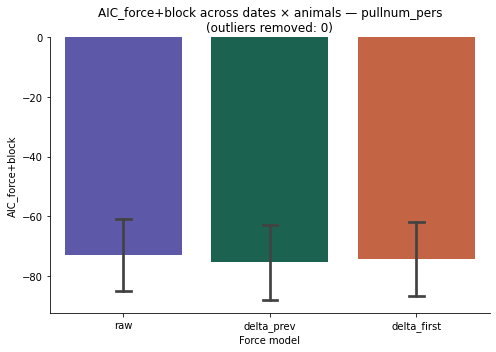

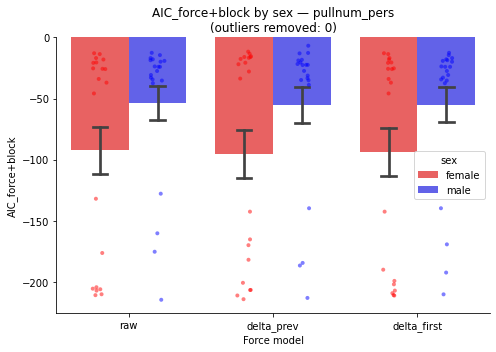

In [20]:
# =========================
# USER SETTINGS
# =========================
xplottype = 'self_force'
condition_to_use = 'self_change_MC'
yplottypes = [
    'succ_rate', 'interpullintv', 'pull_IPI',
    'pullnum_pers', 'succpullnum_pers', 'gazenum_pers'
]

# =========================
# IMPORTS
# =========================
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib.pyplot as plt

# =========================
# DATAFRAME DICTIONARY
# =========================
force_dfs = {
    'raw': summary_all_results,
    'delta_prev': summary_all_results_deltapreforce,
    'delta_first': summary_all_results_deltafirstforce,
}

# =========================
# HELPER: run models on one slice
# =========================
def run_models(df_slice, force_dfs, condition_to_use, xplottype, yplottypes, date, animal):
    results = []
    for yvar in yplottypes:
        for force_name, force_df in force_dfs.items():
            df_force = force_df.loc[force_df.index.isin(df_slice.index)].copy()

            if condition_to_use is not None:
                df_use = df_force[df_force['forceContType'] == condition_to_use].copy()
            else:
                df_use = df_force.copy()

            cols_needed = ['subblockID', xplottype, yvar]
            data = df_use[cols_needed].dropna()

            if len(data) <2:
                continue

            model_block = smf.ols(f"{yvar} ~ subblockID", data=data).fit()
            model_force = smf.ols(f"{yvar} ~ {xplottype} + subblockID", data=data).fit()

            results.append({
                'date': str(date),
                'animal': animal,
                'condition': condition_to_use if condition_to_use else 'all',
                'yvar': yvar,
                'force_model': force_name,
                'xvar': xplottype,
                'n': len(data),
                'AIC_block_only': model_block.aic,
                'AIC_force+block': model_force.aic,
                'ΔAIC_force': model_force.aic - model_block.aic,
                'BIC_block_only': model_block.bic,
                'BIC_force+block': model_force.bic,
                'ΔBIC_force': model_force.bic - model_block.bic
            })
    return results

# =========================
# RUN PER DATE × ANIMAL + POOLED
# =========================
results_all = []

for (date, animal), idx in summary_all_results.groupby(['date', 'self_animal']).groups.items():
    slice_results = run_models(
        df_slice=summary_all_results.loc[idx],
        force_dfs=force_dfs,
        condition_to_use=condition_to_use,
        xplottype=xplottype,
        yplottypes=yplottypes,
        date=date,
        animal=animal
    )
    results_all.extend(slice_results)

# Pooled
pooled_results = run_models(
    df_slice=summary_all_results,
    force_dfs=force_dfs,
    condition_to_use=condition_to_use,
    xplottype=xplottype,
    yplottypes=yplottypes,
    date='ALL',
    animal='ALL'
)
results_all.extend(pooled_results)

# =========================
# RESULTS TABLE
# =========================
results_df = pd.DataFrame(results_all)
results_df = results_df.sort_values(['date', 'animal', 'condition', 'yvar', 'AIC_force+block'])

display(results_df)

print("\n🏆 Best force model per date × animal × behavior (by AIC):")
display(
    results_df.loc[
        results_df.groupby(['date', 'animal', 'condition', 'yvar'])['AIC_force+block'].idxmin()
    ].sort_values(['date', 'animal', 'condition', 'yvar'])
)


# =========================
# VIOLIN PLOT
# =========================
yvar_to_plot = 'pullnum_pers'
metric = 'AIC_force+block'  # or 'ΔAIC_force'

plot_df = results_df[
    (results_df['yvar'] == yvar_to_plot) &
    (results_df['date'] != 'ALL')
].copy()

# --- Remove outliers (IQR across all models) ---
def remove_outliers_iqr(df, col, k=1.5):
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    return df[df[col].between(q1 - k * iqr, q3 + k * iqr)]

n_before = len(plot_df)
plot_df = remove_outliers_iqr(plot_df, metric, k=1.5)
# plot_df = plot_df[plot_df[metric] >= -100]
n_after = len(plot_df)
print(f"Outliers removed: {n_before - n_after} ({n_before} → {n_after} points)")
print(plot_df.groupby('force_model')[metric].describe().round(2))

# --- Plot ---
order = ['raw', 'delta_prev', 'delta_first']
palette = {'raw': '#534AB7', 'delta_prev': '#0F6E56', 'delta_first': '#D85A30'}

fig, ax = plt.subplots(figsize=(7, 5))

sns.barplot(
    data=plot_df,
    x='force_model', y=metric,
    order=order, palette=palette,
    estimator='mean',
    errorbar='se',
    capsize=0.1,
    linewidth=1.2,
    ax=ax
)
if 0:
    sns.stripplot(
        data=plot_df,
        x='force_model', y=metric,
        order=order,
        color='gray', edgecolor='white',
        size=5, jitter=True, alpha=0.5, linewidth=0.5,
        ax=ax
    )

ax.set_title(f'{metric} across dates × animals — {yvar_to_plot}\n(outliers removed: {n_before - n_after})')
ax.set_xlabel('Force model')
ax.set_ylabel(metric)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
# plt.show()


# =========================
# AIC BY SEX
# =========================
male_animals = ['dannon', 'dodson', 'vermelho']
plot_df_sex = plot_df.copy()
plot_df_sex['sex'] = np.where(
    plot_df_sex['animal'].str.lower().isin(male_animals), 'male', 'female')

print(plot_df_sex.groupby('sex')['animal'].unique())  # sanity check
print(plot_df_sex.groupby(['sex', 'force_model'])[metric]
      .agg(n='count', mean='mean', median='median', std='std').round(2))

sexcolors = {'female': 'red', 'male': 'blue'}

fig2, ax2 = plt.subplots(figsize=(7, 5))
sns.barplot(
    data=plot_df_sex,
    x='force_model', y=metric, hue='sex',
    order=order, hue_order=['female', 'male'], palette=sexcolors,
    estimator='mean', errorbar='se', capsize=0.1,
    alpha=0.7, linewidth=1.2, ax=ax2
)
sns.stripplot(
    data=plot_df_sex,
    x='force_model', y=metric, hue='sex',
    order=order, hue_order=['female', 'male'], palette=sexcolors,
    dodge=True, size=4, jitter=True, alpha=0.5, legend=False, ax=ax2
)

ax2.set_title(f'{metric} by sex — {yvar_to_plot}\n(outliers removed: {n_before - n_after})')
ax2.set_xlabel('Force model')
ax2.set_ylabel(metric)
ax2.spines[['top', 'right']].set_visible(False)
ax2.legend(title='sex')
plt.tight_layout()

    
    
# ================= SAVE =================
savefigs = 1

if savefigs:

    figsavefolder = (
        data_saved_folder +
        'figs_for_BasicBhvAna_singlecam_wholebodylabels_allsessions_basicEvents_allanimal_summary/' +
        savefile_sufix + '/' + cameraID + '/'
    )

    os.makedirs(figsavefolder, exist_ok=True)

    fig.savefig(
        figsavefolder +
        yvar_to_plot +
        "_AIC_comparison.pdf"
    )
    fig2.savefig(figsavefolder + yvar_to_plot + "_AIC_comparison_bysex.pdf")
    
# =========================
# BEST MODEL AT SESSION-POPULATION LEVEL
# =========================
print("\n📊 Session-population level: mean AIC per force model")

summary = (
    plot_df.groupby('force_model')[metric]
    .agg(n='count', mean='mean', median='median', std='std')
    .reindex(order)
    .round(3)
)
summary['rank'] = summary['mean'].rank().astype(int)
display(summary.sort_values('mean'))

best_model = summary['mean'].idxmin()
print(f"\n🏆 Best model overall (lowest mean {metric}): {best_model}")

# --- Win rate: how often is each model best per date × animal ---
print("\n📊 Win rate: fraction of date×animal sessions where each model has lowest AIC")

win_counts = (
    plot_df.loc[plot_df.groupby(['date', 'animal'])[metric].idxmin()]
    ['force_model'].value_counts()
)
win_rate = (win_counts / win_counts.sum()).round(3).rename('win_rate').to_frame()
win_rate['n_wins'] = win_counts
display(win_rate.reindex(order).fillna(0))

### plot the summarizing figures with all animals
#### different variables plot against self force level or other force level
#### separating condition (self sr, other sr, self mc, other mc etc)
#### choose the version of the variables - raw, normalized force, or delta force; raw or blockiD regressed residuals

/home/ws523/.conda/envs/DLC/lib/python3.8/site-packages/statsmodels/regression/mixed_linear_model.py:1557: RuntimeWarning: divide by zero encountered in log
  likeval -= (self.n_totobs - self.k_fe) * np.log(qf) / 2.
/home/ws523/.conda/envs/DLC/lib/python3.8/site-packages/statsmodels/regression/mixed_linear_model.py:1797: RuntimeWarning: invalid value encountered in divide
  score_re += 0.5 * fac * rvavr[0:self.k_re2] / rvir
/home/ws523/.conda/envs/DLC/lib/python3.8/site-packages/numpy/linalg/linalg.py:2079: RuntimeWarning: invalid value encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/home/ws523/.conda/envs/DLC/lib/python3.8/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/ws523/.conda/envs/DLC/lib/python3.8/site-packages/statsmodels/regression/mixed_linear_model.py:2207: ConvergenceWarning: MixedL

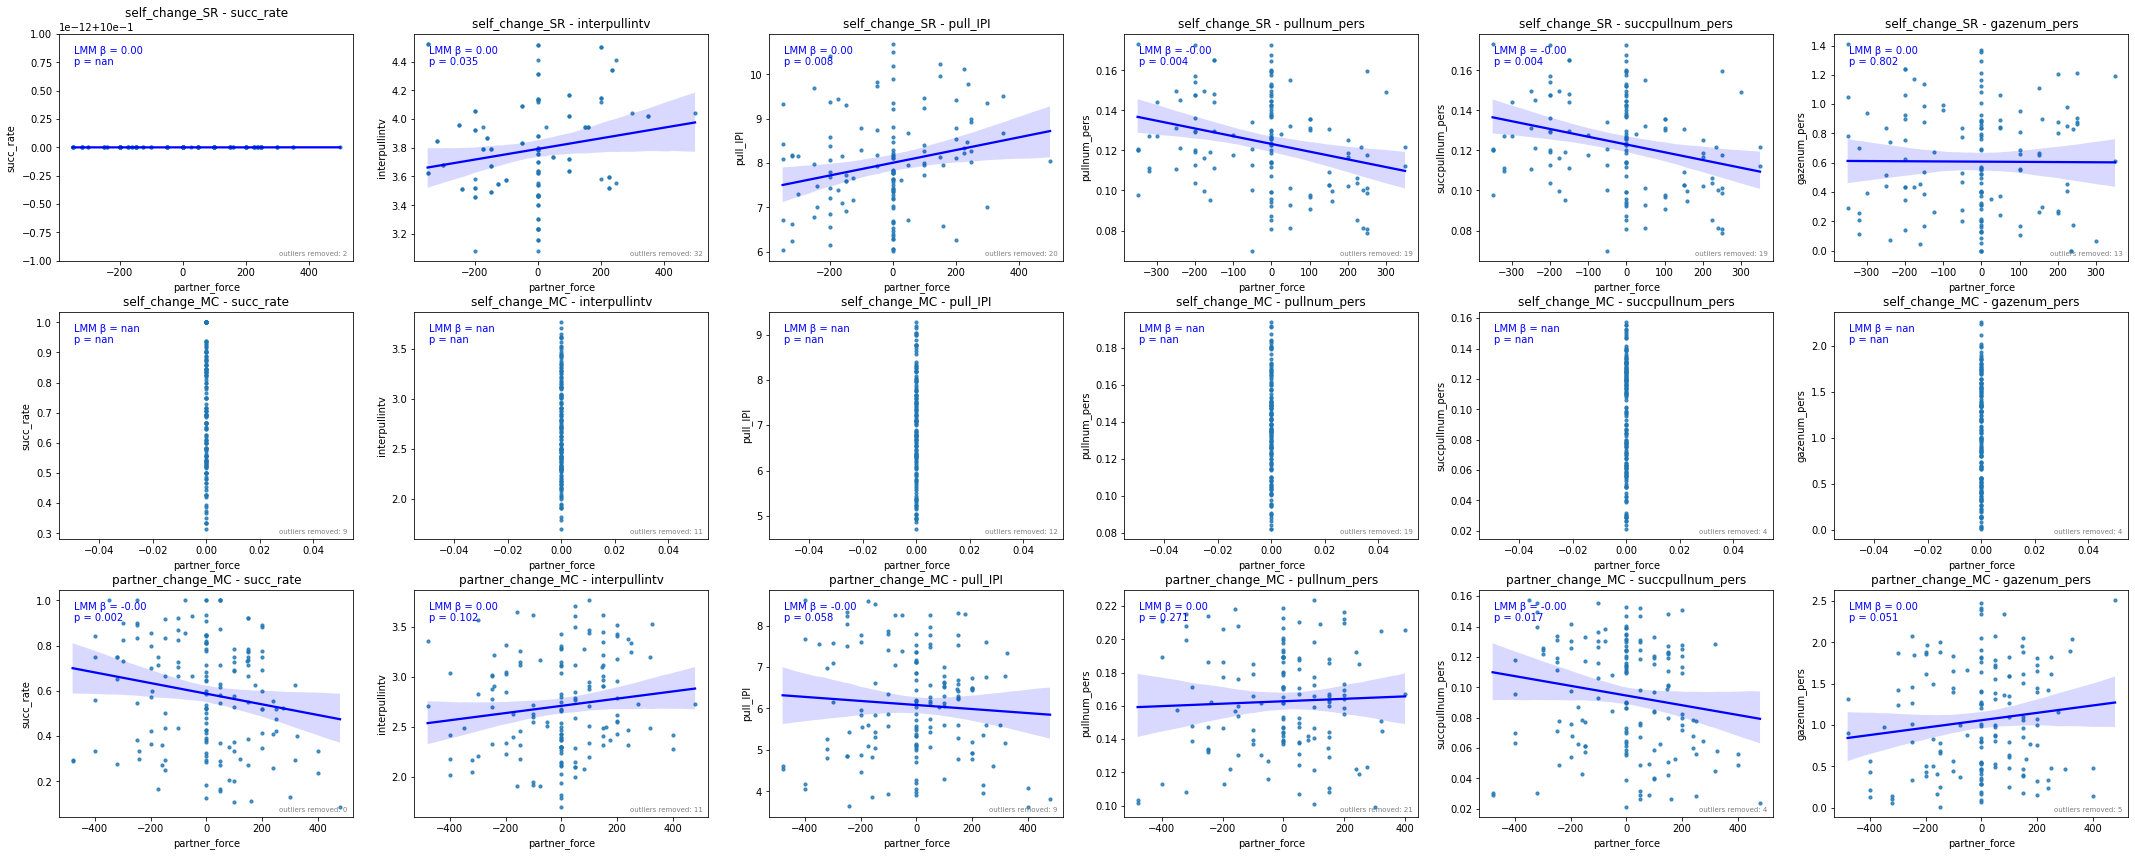

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn
import scipy.stats as st
import statsmodels.formula.api as smf
import os

# datatypename = ''
# summary_all_tgt = summary_all_results

datatypename = 'deltapreforce'
summary_all_tgt = summary_all_results_deltapreforce

# datatypename = 'blockIDregressed_deltapreforce'
# summary_all_tgt = summary_all_results_blockIDregressed_deltapreforce

nTrialConds = summary_all_tgt['forceContType'].nunique()

xplottype = 'partner_force'   # 'self_force' or 'partner_force' or 'subblockID'

yplottypes = [
    'succ_rate','interpullintv','pull_IPI',
    'pullnum_pers','succpullnum_pers','gazenum_pers'
]

nyplottypes = len(yplottypes)

# ---- y-axis outlier removal (per panel, before plotting/stats) ----
remove_y_outliers = True
outlier_k = 0.75               # IQR multiplier: keep q1 - k*IQR <= y <= q3 + k*IQR
outlier_by_animal = False   # False: one IQR across the whole panel
                              # True:  IQR computed separately for each animal in the panel

def remove_outliers_y(data, y, k=1.5):
    """Keep rows whose y lies within [q1 - k*IQR, q3 + k*IQR]."""
    q1, q3 = data[y].quantile([0.25, 0.75])
    iqr = q3 - q1
    return data[data[y].between(q1 - k * iqr, q3 + k * iqr)]

# ================= FIGURE SETUP =================
fig, axes = plt.subplots(
    nTrialConds, nyplottypes,
    figsize=(5 * nyplottypes, 4 * nTrialConds),
    squeeze=False
)
fig.tight_layout(pad=3.0)

unique_conditions = summary_all_tgt['forceContType'].unique()

# ================= MAIN LOOP =================
for i, condition in enumerate(unique_conditions):

    condition_data = summary_all_tgt[
        summary_all_tgt['forceContType'] == condition
    ]

    for j, yplot in enumerate(yplottypes):

        ax = axes[i, j]

        data_cleaned = condition_data[
            ['self_animal', xplottype, yplot]
        ].replace([np.inf, -np.inf], np.nan).dropna()

        # ---------- Y OUTLIER REMOVAL ----------
        n_out = 0
        if remove_y_outliers and len(data_cleaned) > 0:
            n_before = len(data_cleaned)
            if outlier_by_animal:
                data_cleaned = (data_cleaned.groupby('self_animal', group_keys=False)
                                    .apply(lambda g: remove_outliers_y(g, yplot, outlier_k)))
            else:
                data_cleaned = remove_outliers_y(data_cleaned, yplot, outlier_k)
            n_out = n_before - len(data_cleaned)

        if len(data_cleaned) < 5:
            continue

        if remove_y_outliers:
            ax.text(0.98, 0.02, f"outliers removed: {n_out}",
                    transform=ax.transAxes, ha='right', va='bottom', fontsize=7, color='gray')

        # # remove when the delta force is zero
        # data_cleaned = data_cleaned[data_cleaned['self_force']!=0]


        # ---------- PLOT (same as before) ----------
        seaborn.regplot(
            data=data_cleaned,
            x=xplottype,
            y=yplot,
            ax=ax,
            scatter_kws={'s': 10},
            line_kws={'color': 'blue'}
        )

        # ---------- LMM ----------
        if 1:
            data_lmm = data_cleaned.rename(
                columns={xplottype: 'x', yplot: 'y'}
            )

            try:
                model = smf.mixedlm(
                    "y ~ x",
                    data=data_lmm,
                    groups=data_lmm["self_animal"]
                )
                fit = model.fit(method='lbfgs', disp=False)

                beta = fit.params['x']
                p_value = fit.pvalues['x']

            except:
                beta = np.nan
                p_value = np.nan

            stat_label = 'LMM'

        # ---------- REGRESSION ----------
        if 0:
            data_reg = data_cleaned[[xplottype, yplot]].dropna().rename(
                columns={xplottype: 'x', yplot: 'y'}
            )
            try:
                slope, intercept, r, p_value, se = st.linregress(data_reg['x'], data_reg['y'])
                beta = slope
            except:
                beta = np.nan
                p_value = np.nan

            stat_label = 'Reg'

        ax.text(
            0.05, 0.95,
            f"{stat_label} β = {beta:.2f}\np = {p_value:.3f}",
            transform=ax.transAxes,
            fontsize=10,
            verticalalignment='top',
            color='blue'
        )

        # ---------- LABELS ----------
        ax.set_title(f"{condition} - {yplot}")

        if i == nTrialConds - 1:
            ax.set_xlabel(xplottype)

        if j == 0:
            ax.set_ylabel(yplot)

# plt.show()

# ================= SAVE =================
savefigs = 1

if savefigs:

    figsavefolder = (
        data_saved_folder +
        'figs_for_BasicBhvAna_singlecam_wholebodylabels_allsessions_basicEvents_allanimal_summary/' +
        savefile_sufix + '/' + cameraID + '/'
    )

    os.makedirs(figsavefolder, exist_ok=True)

    fig.savefig(
        figsavefolder +
        xplottype +
        "level_vs_bhvvariables_allanimal_allcondition_versionof_" +
        datatypename +
        ".pdf"
    )

In [ ]:
data_cleaned[data_cleaned['self_force']!=0]

### plot the summarizing figures with all animals - plot each animal separately
#### different variables plot against self force level or other force level
#### separating condition (self sr, other sr, self mc, other mc etc)
#### choose the version of the variables - raw, normalized force, or delta force; raw or blockiD regressed residuals

/home/ws523/.conda/envs/DLC/lib/python3.8/site-packages/scipy/stats/_stats_py.py:4424: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(stats.ConstantInputWarning(msg))


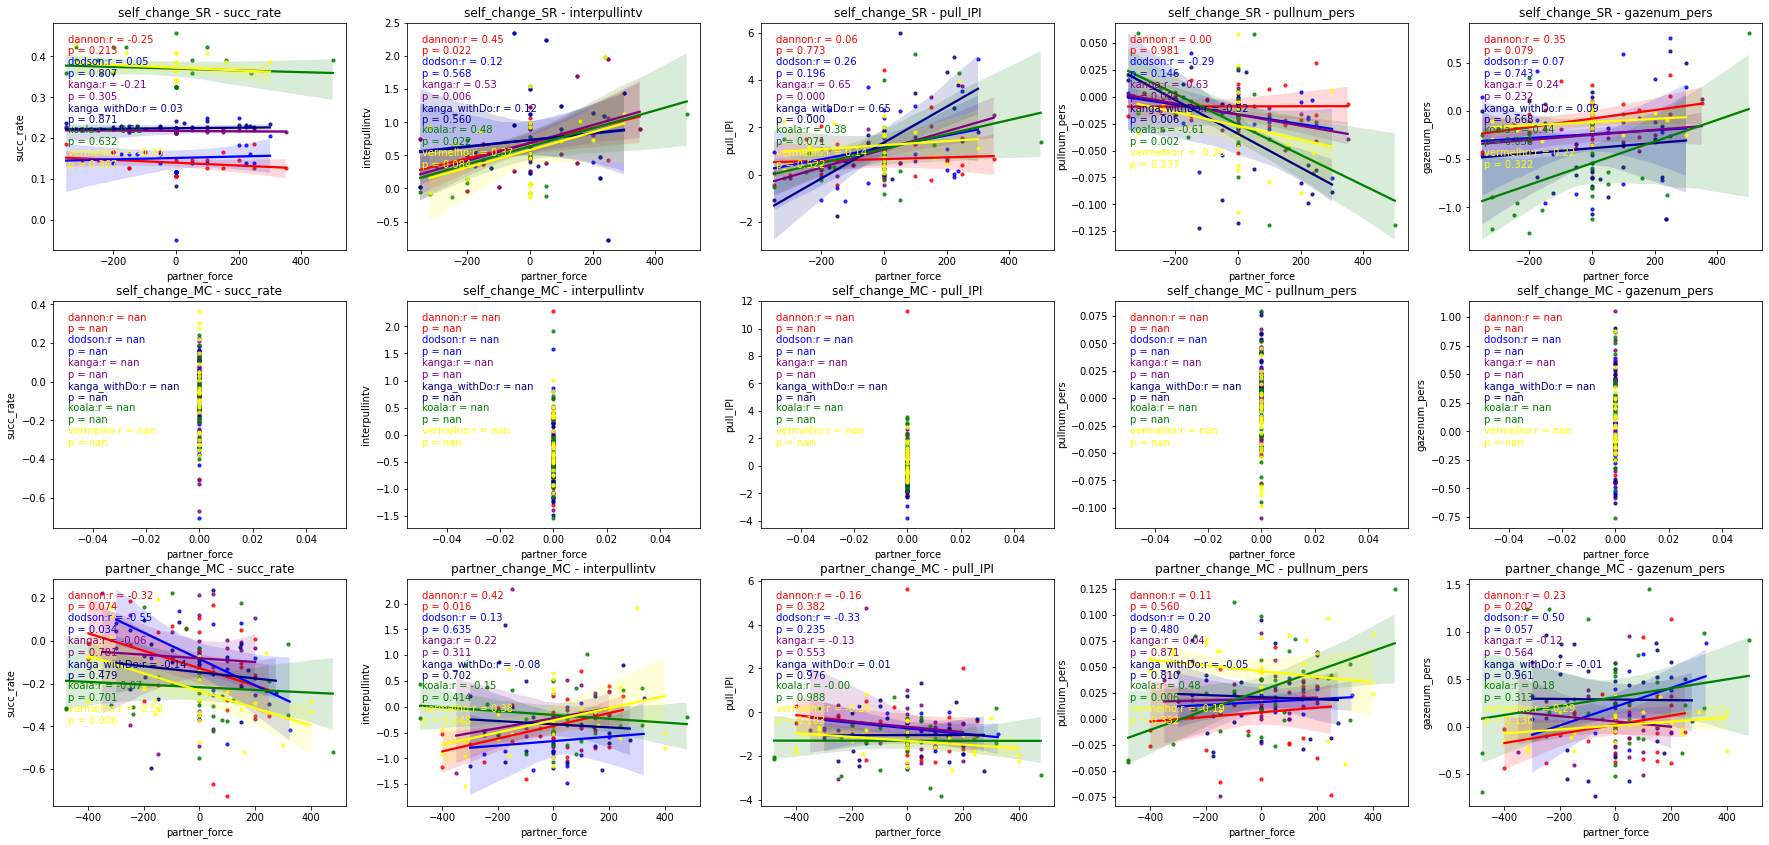

In [45]:
# datatypename = '' # 'blockIDregressed_normforce','blockIDregressed_deltafirstforce','blockIDregressed_deltapreforce'
# summary_all_tgt = summary_all_results
# datatypename = 'deltapreforce'
# summary_all_tgt = summary_all_results_deltapreforce
datatypename = 'blockIDregressed_deltapreforce'
summary_all_tgt = summary_all_results_blockIDregressed_deltapreforce


nTrialConds = np.shape(np.unique(summary_all_tgt['forceContType']))[0]

xplottype = 'partner_force' # 'self_focce' or 'partner_force' or 'subblockID'
yplottypes = ['succ_rate','interpullintv','pull_IPI','pullnum_pers','gazenum_pers']
nyplottypes = np.shape(yplottypes)[0]

animalcolors = ['red','blue','purple','darkblue','green','yellow']

# Set up the figure grid
fig, axes = plt.subplots(nTrialConds, nyplottypes, 
                         figsize=(5 * nyplottypes, 4 * nTrialConds), 
                         sharex=False, sharey=False)
fig.tight_layout(pad=3.0)

# Plotting each unique condition and y-axis type
unique_conditions = summary_all_tgt['forceContType'].unique()

for i, condition in enumerate(unique_conditions):
    # Filter data for the current condition
    condition_data = summary_all_tgt[summary_all_tgt['forceContType'] == condition]
    
    selfanimals = np.unique(condition_data['self_animal'])
    # selfanimals = ['kanga']
    nanimals = np.shape(selfanimals)[0]
    
    for ianimal in np.arange(0,nanimals,1):
        
        selfanimal = selfanimals[ianimal]
        
        condition_data_ianimal = condition_data[condition_data['self_animal']==selfanimal]
    
        for j, yplot in enumerate(yplottypes):
            ax = axes[i, j] if nTrialConds > 1 else axes[j]  # Adjust for single-row cases

            # Drop rows with NaN or inf in the columns of interest
            data_cleaned = condition_data_ianimal[[xplottype, yplot]].replace([np.inf, -np.inf], np.nan).dropna()

            # Create a regression plot for each y-axis type within the current condition
            seaborn.regplot(data=data_cleaned, x=xplottype, y=yplot, ax=ax, 
                            scatter_kws={'s': 10, 'color': animalcolors[ianimal]}, 
                            line_kws={'color': animalcolors[ianimal]})

            try:
            # Calculate correlation coefficient and p-value
                r_value, p_value = st.pearsonr(data_cleaned[xplottype], data_cleaned[yplot])
            except:
                r_value = np.nan
                p_value = np.nan

            # Add text for the correlation statistics
            ax.text(0.05, 0.95-0.1*ianimal, selfanimal+':'+f"r = {r_value:.2f}\np = {p_value:.3f}", 
                    transform=ax.transAxes, fontsize=10, verticalalignment='top', color=animalcolors[ianimal])


            # Set titles and labels
            ax.set_title(f"{condition} - {yplot}")
            if i == nTrialConds - 1:
                ax.set_xlabel(xplottype)
            if j == 0:
                ax.set_ylabel(yplot)

plt.show()

savefigs = 1
if savefigs:
    figsavefolder = data_saved_folder+'figs_for_BasicBhvAna_singlecam_wholebodylabels_allsessions_basicEvents_allanimal_summary/'+savefile_sufix+'/'+cameraID+'/'
    if not os.path.exists(figsavefolder):
        os.makedirs(figsavefolder)
    fig.savefig(figsavefolder+xplottype+"level_vs_bhvvariables_separatedanimal_allcondition_versionof_"+datatypename+".pdf")



### plot the summarizing figures with all animals - plot each day separately; color coded the animal ID
#### different variables plot against self force level or other force level
#### separating condition (self sr, other sr, self mc, other mc etc)
#### choose the version of the variables - raw, normalized force, or delta force; raw or blockiD regressed residuals

/home/ws523/.conda/envs/DLC/lib/python3.8/site-packages/scipy/stats/_stats_mstats_common.py:182: RuntimeWarning: invalid value encountered in scalar divide
  slope = ssxym / ssxm
/home/ws523/.conda/envs/DLC/lib/python3.8/site-packages/scipy/stats/_stats_mstats_common.py:196: RuntimeWarning: invalid value encountered in sqrt
  t = r * np.sqrt(df / ((1.0 - r + TINY)*(1.0 + r + TINY)))
/home/ws523/.conda/envs/DLC/lib/python3.8/site-packages/scipy/stats/_stats_mstats_common.py:199: RuntimeWarning: invalid value encountered in scalar divide
  slope_stderr = np.sqrt((1 - r**2) * ssym / ssxm / df)


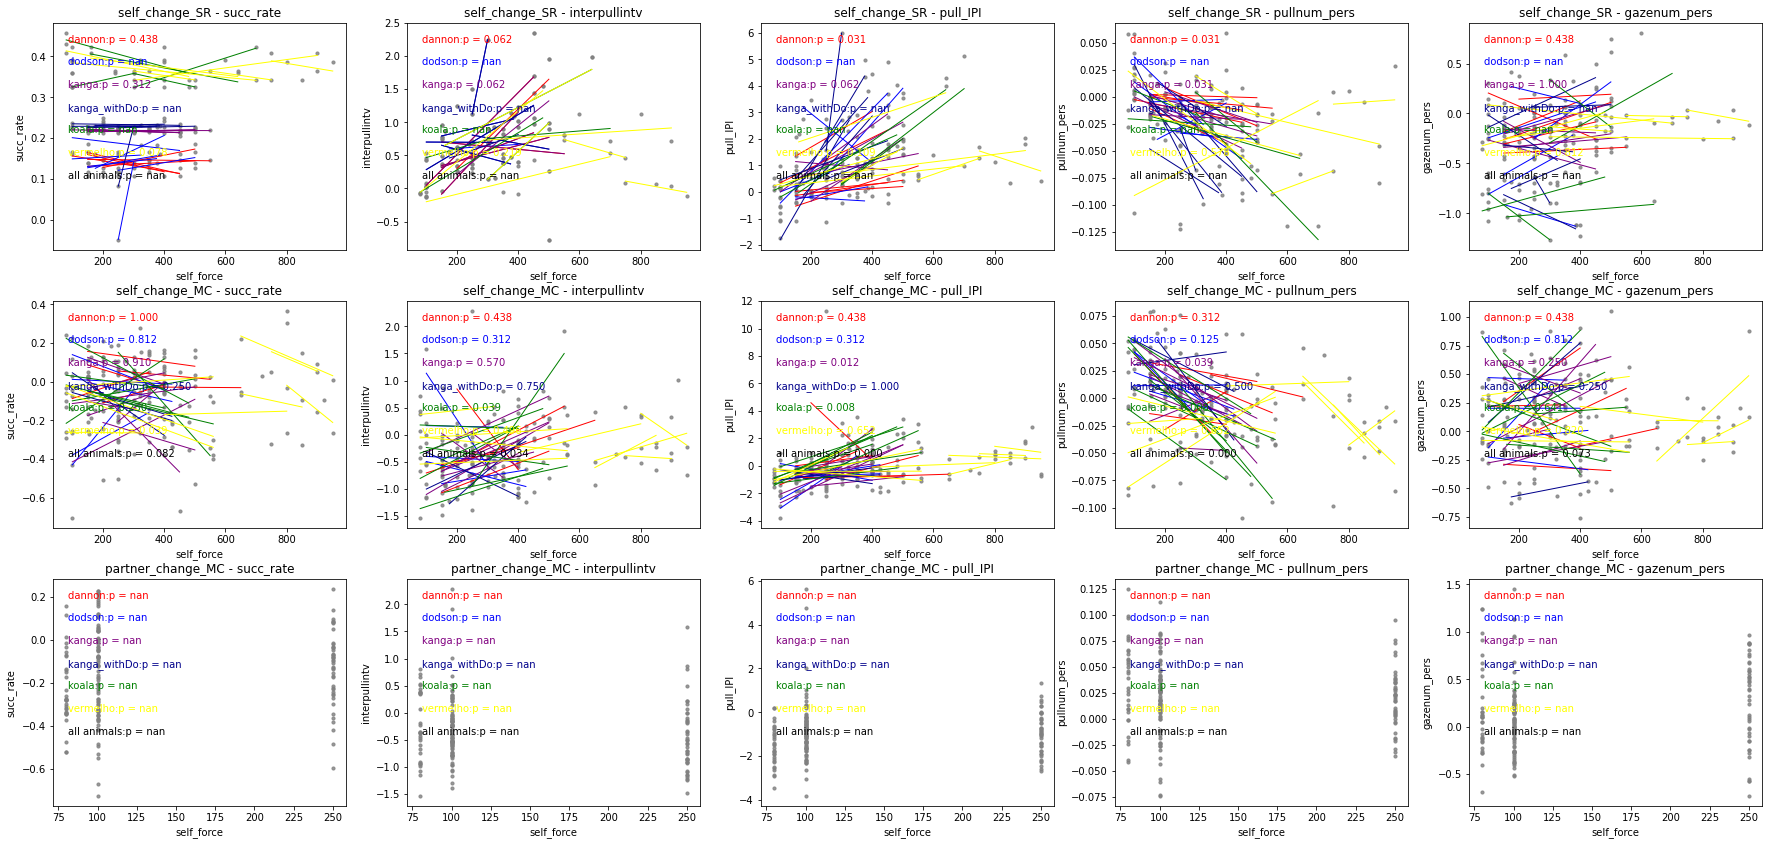

In [27]:
# datatypename = '' # 'blockIDregressed_normforce','blockIDregressed_deltafirstforce','blockIDregressed_deltapreforce'
# summary_all_tgt = summary_all_results
datatypename = 'blockIDregressed'
summary_all_tgt = summary_all_results_blockIDregressed

nTrialConds = np.shape(np.unique(summary_all_tgt['forceContType']))[0]

xplottype = 'self_force' # 'self_force' or 'partner_force' or 'subblockID'
yplottypes = ['succ_rate','interpullintv','pull_IPI','pullnum_pers','gazenum_pers']
nyplottypes = np.shape(yplottypes)[0]

animalcolors = ['red','blue','purple','darkblue','green','yellow']

slopes_all_result = pd.DataFrame(columns=['self_animal','date','tasktype','xplottype','yplottype','slope',])

# Set up the figure grid
fig, axes = plt.subplots(nTrialConds, nyplottypes, 
                         figsize=(5 * nyplottypes, 4 * nTrialConds), 
                         sharex=False, sharey=False)
fig.tight_layout(pad=3.0)

# Plotting each unique condition and y-axis type
unique_conditions = summary_all_tgt['forceContType'].unique()

for i, condition in enumerate(unique_conditions):
    # Filter data for the current condition
    condition_data = summary_all_tgt[summary_all_tgt['forceContType'] == condition]
    
    selfanimals = np.unique(condition_data['self_animal'])
    nanimals = np.shape(selfanimals)[0]
    
    for j, yplot in enumerate(yplottypes):
        ax = axes[i, j] if nTrialConds > 1 else axes[j]  # Adjust for single-row cases
            
        # plot for each animal separately
        for ianimal in np.arange(0,nanimals,1):

            selfanimal = selfanimals[ianimal]

            condition_data_ianimal = condition_data[condition_data['self_animal']==selfanimal]

            sessiondates = np.unique(condition_data_ianimal['date'])
            nsessiondates = np.shape(sessiondates)[0]

            for isessdate in np.arange(0,nsessiondates,1):

                sessiondate = sessiondates[isessdate]

                condition_data_ianimal_idate = condition_data_ianimal[condition_data_ianimal['date']==sessiondate]

                # Drop rows with NaN or inf in the columns of interest
                data_cleaned = condition_data_ianimal_idate[[xplottype, yplot]].replace([np.inf, -np.inf], np.nan).dropna()

                # Create a regression plot for each y-axis type within the current condition
                seaborn.regplot(data=data_cleaned, x=xplottype, y=yplot, ax=ax, ci=None,
                                scatter_kws={'s':10,'color':'gray'}, 
                                line_kws={'color': animalcolors[ianimal],'linewidth': 1})

                try:
                    slope, intercept, r_value, p_value, std_err = st.linregress(data_cleaned[xplottype], data_cleaned[yplot])
                except:
                    slope = np.nan
                slopes_all_result = slopes_all_result.append({'self_animal':selfanimal,
                                                              'date':sessiondate,
                                                              'tasktype':condition,
                                                              'xplottype':xplottype,
                                                              'yplottype':yplot,
                                                              'slope':slope,
                                                              'r_value':r_value,
                                                              'p_value':p_value,
                                                              
                                                             }, ignore_index=True)
            
            # run wilcoxcon on the slope
            ind_slope_tgt = (slopes_all_result['self_animal']==selfanimal) &\
                            (slopes_all_result['tasktype']==condition) &\
                            (slopes_all_result['xplottype']==xplottype) &\
                            (slopes_all_result['yplottype']==yplot)
            slopes_tgt = slopes_all_result[ind_slope_tgt]
                            
            try:
                _,p_value = st.wilcoxon(slopes_tgt['slope'])
            except:
                p_value = np.nan 
                
            # Add text for the correlation statistics
            ax.text(0.05, 0.95-0.1*ianimal, selfanimal+':'+f"p = {p_value:.3f}", 
                    transform=ax.transAxes, fontsize=10, verticalalignment='top', color=animalcolors[ianimal])

        
        # run wilcoxcon on the slope
        ind_slope_tgt = (slopes_all_result['tasktype']==condition) &\
                        (slopes_all_result['xplottype']==xplottype) &\
                        (slopes_all_result['yplottype']==yplot)
        slopes_tgt = slopes_all_result[ind_slope_tgt]

        try:
            _,p_value = st.wilcoxon(slopes_tgt['slope'])
        except:
            p_value = np.nan 
         
        # Add text for the correlation statistics
        ax.text(0.05, 0.95-0.1*nanimals, 'all animals:'+f"p = {p_value:.3f}", 
                transform=ax.transAxes, fontsize=10, verticalalignment='top', color='k')

        # Set titles and labels
        ax.set_title(f"{condition} - {yplot}")
        if i == nTrialConds - 1:
            ax.set_xlabel(xplottype)
        if j == 0:
            ax.set_ylabel(yplot)

plt.show()

savefigs = 1
if savefigs:
    figsavefolder = data_saved_folder+'figs_for_BasicBhvAna_singlecam_wholebodylabels_allsessions_basicEvents_allanimal_summary/'+savefile_sufix+'/'+cameraID+'/'
    if not os.path.exists(figsavefolder):
        os.makedirs(figsavefolder)
    fig.savefig(figsavefolder+xplottype+"level_vs_bhvvariables_separatedanimal_separatedays_allcondition_versionof_"+datatypename+".pdf")



In [29]:
ind_tgt = (slopes_all_result['tasktype']=='self_change_MC') &\
          (slopes_all_result['xplottype']=='self_force') &\
          (slopes_all_result['yplottype']=='pullnum_pers') &\
          (slopes_all_result['p_value']<0.05) 

slopes_all_result[ind_tgt]

,self_animal,date,tasktype,xplottype,yplottype,slope,p_value,r_value
339,dodson,20250520,self_change_MC,self_force,pullnum_pers,-0.000103,0.027235,-0.862044
341,kanga,20240910,self_change_MC,self_force,pullnum_pers,-0.000015,0.000000,-1.000000
351,kanga_withDo,20250516_MC,self_change_MC,self_force,pullnum_pers,-0.000364,0.016852,-0.983148
356,koala,20240318,self_change_MC,self_force,pullnum_pers,-0.000321,0.035057,-0.998484
361,vermelho,20240307,self_change_MC,self_force,pullnum_pers,0.000019,0.000000,1.000000


### plot the summarizing figures with all animals - plot male and female separately

sex
female    [koala, kanga, kanga_withDo]
male        [vermelho, dannon, dodson]
Name: self_animal, dtype: object


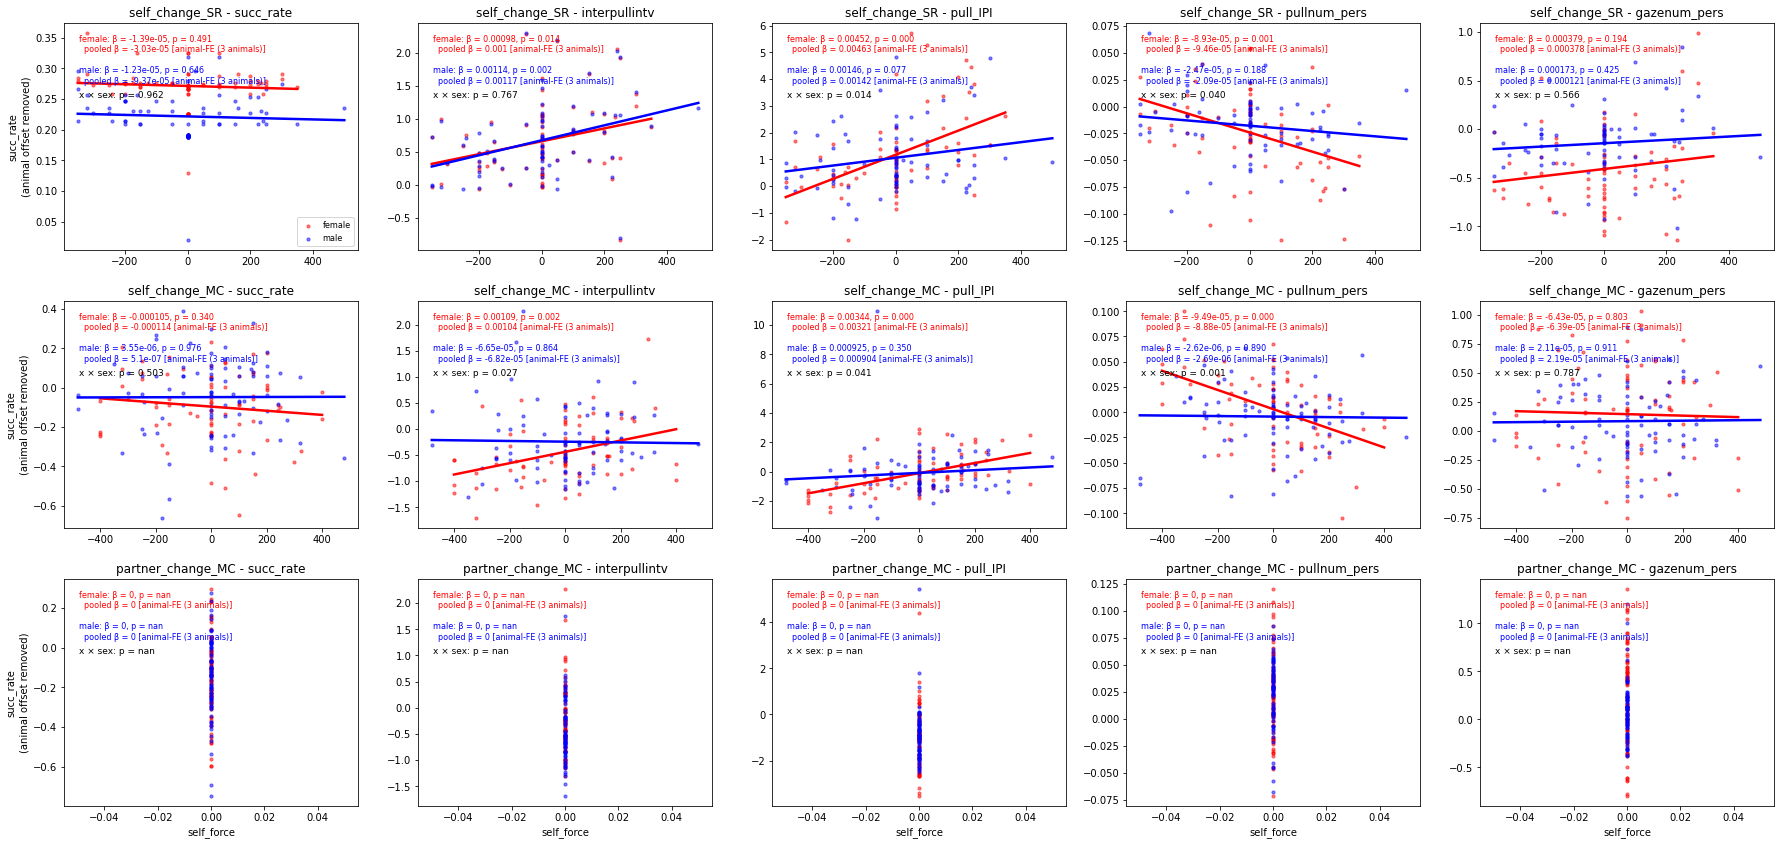

            condition              y   model                       term      beta         p  beta_pooled_ols  n_obs                 method
0      self_change_SR      succ_rate  female                 self_force -0.000014  0.491394    -3.033723e-05     75  animal-FE (3 animals)
1      self_change_SR      succ_rate    male                 self_force -0.000012  0.645766    -9.368963e-05     75  animal-FE (3 animals)
2      self_change_SR      succ_rate   x*sex  self_force:C(sex)[T.male]  0.000002  0.961934              NaN    150              animal-FE
3      self_change_SR  interpullintv  female                 self_force  0.000980  0.014153     1.003724e-03     75  animal-FE (3 animals)
4      self_change_SR  interpullintv    male                 self_force  0.001136  0.002185     1.171371e-03     75  animal-FE (3 animals)
5      self_change_SR  interpullintv   x*sex  self_force:C(sex)[T.male]  0.000157  0.766972              NaN    150              animal-FE
6      self_change_SR      

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import os

# ------------------------------------------------------------------
# data selection
# ------------------------------------------------------------------
# datatypename = ''  # 'blockIDregressed_normforce','blockIDregressed_deltafirstforce','blockIDregressed_deltapreforce'
# summary_all_tgt = summary_all_results
# datatypename = 'deltapreforce'
# summary_all_tgt = summary_all_results_deltapreforce
datatypename = 'blockIDregressed_deltapreforce'
summary_all_tgt = summary_all_results_blockIDregressed_deltapreforce

xplottype = 'self_force'  # 'self_force' or 'partner_force' or 'subblockID'
yplottypes = ['succ_rate', 'interpullintv', 'pull_IPI', 'pullnum_pers', 'gazenum_pers']
nyplottypes = len(yplottypes)

# ------------------------------------------------------------------
# sex assignment
# ------------------------------------------------------------------
male_animals = ['dannon', 'dodson', 'vermelho']
summary_all_tgt = summary_all_tgt.copy()
summary_all_tgt['sex'] = np.where(
    summary_all_tgt['self_animal'].str.lower().isin(male_animals), 'male', 'female')
print(summary_all_tgt.groupby('sex')['self_animal'].unique())  # sanity check

sexes = ['female', 'male']
sexcolors = {'female': 'red', 'male': 'blue'}


# ------------------------------------------------------------------
# Fixed-effects regression: y ~ x + C(animal)
#   -> slope is the WITHIN-animal force effect (animal baselines removed)
#   -> closed-form OLS, so no optimizer / convergence problems
# ------------------------------------------------------------------
def fit_within_animal(d, x, y):
    n_animals = d['self_animal'].nunique()
    if n_animals >= 2:
        fit = smf.ols(f"{y} ~ {x} + C(self_animal)", data=d).fit()
        label = f'animal-FE ({n_animals} animals)'
    else:
        fit = smf.ols(f"{y} ~ {x}", data=d).fit()
        label = 'OLS (1 animal)'
    beta, pval = fit.params[x], fit.pvalues[x]

    # each animal's intercept = model prediction at x = 0
    animals = d['self_animal'].unique()
    pred0 = fit.predict(pd.DataFrame({x: 0.0, 'self_animal': animals}))
    a_intercept = dict(zip(animals, np.asarray(pred0)))
    mean_intercept = np.mean(list(a_intercept.values()))

    # adjusted data: remove each animal's offset from the average animal
    offset = d['self_animal'].map(a_intercept) - mean_intercept
    y_adj = d[y] - offset
    return dict(beta=beta, p=pval, b0=mean_intercept, y_adj=y_adj,
                a_intercept=a_intercept, label=label)


# ------------------------------------------------------------------
# plotting
# ------------------------------------------------------------------
unique_conditions = summary_all_tgt['forceContType'].unique()
nTrialConds = len(unique_conditions)

fig, axes = plt.subplots(nTrialConds, nyplottypes,
                         figsize=(5 * nyplottypes, 4 * nTrialConds),
                         sharex=False, sharey=False, squeeze=False)
fig.tight_layout(pad=3.0)

stats_rows = []

for i, condition in enumerate(unique_conditions):
    condition_data = summary_all_tgt[summary_all_tgt['forceContType'] == condition]

    for j, yplot in enumerate(yplottypes):
        ax = axes[i, j]

        data_cond = condition_data[['self_animal', 'sex', xplottype, yplot]] \
            .replace([np.inf, -np.inf], np.nan).dropna().copy()
        data_cond[xplottype] = data_cond[xplottype].astype(float)
        data_cond[yplot] = data_cond[yplot].astype(float)

        # ---- per-sex within-animal slope ----
        for k, sex in enumerate(sexes):
            d = data_cond[data_cond['sex'] == sex]
            if len(d) < 5:
                continue
            try:
                r = fit_within_animal(d, xplottype, yplot)
                beta, pval, label = r['beta'], r['p'], r['label']

                # dots: animal-offset-adjusted data
                ax.scatter(d[xplottype], r['y_adj'], s=10,
                           color=sexcolors[sex], alpha=0.5, label=sex)
                # line: average animal's intercept + within-animal slope
                xs = np.linspace(d[xplottype].min(), d[xplottype].max(), 50)
                ax.plot(xs, r['b0'] + beta * xs, color=sexcolors[sex], lw=2.5)

                # pooled OLS (ignores animal) for comparison
                beta_ols = smf.ols(f"{yplot} ~ {xplottype}", data=d).fit().params[xplottype]
            except Exception as e:
                print(f"{condition} {yplot} {sex}: {e}")
                beta, pval, beta_ols, label = np.nan, np.nan, np.nan, 'failed'

            ax.text(0.05, 0.95 - 0.14 * k,
                    f"{sex}: β = {beta:.3g}, p = {pval:.3f}\n"
                    f"  pooled β = {beta_ols:.3g} [{label}]",
                    transform=ax.transAxes, fontsize=8, va='top', color=sexcolors[sex])

            stats_rows.append(dict(condition=condition, y=yplot, model=sex,
                                   term=xplottype, beta=beta, p=pval,
                                   beta_pooled_ols=beta_ols, n_obs=len(d), method=label))

        # ---- sex difference in slope: y ~ x + x:sex + C(animal) ----
        # (sex main effect is absorbed by the animal terms, since animal is nested in sex)
        if data_cond['sex'].nunique() == 2:
            int_term = f"{xplottype}:C(sex)[T.male]"
            try:
                fit_int = smf.ols(f"{yplot} ~ {xplottype} + {xplottype}:C(sex) + C(self_animal)",
                                  data=data_cond).fit()
                b_int = fit_int.params.get(int_term, np.nan)
                p_int = fit_int.pvalues.get(int_term, np.nan)
            except Exception as e:
                print(f"{condition} {yplot} interaction: {e}")
                b_int, p_int = np.nan, np.nan
            ax.text(0.05, 0.70, f"x × sex: p = {p_int:.3f}",
                    transform=ax.transAxes, fontsize=9, va='top', color='k')
            stats_rows.append(dict(condition=condition, y=yplot, model='x*sex',
                                   term=int_term, beta=b_int, p=p_int,
                                   n_obs=len(data_cond), method='animal-FE'))

        ax.set_title(f"{condition} - {yplot}")
        if i == nTrialConds - 1:
            ax.set_xlabel(xplottype)
        if j == 0:
            ax.set_ylabel(f"{yplot}\n(animal offset removed)")
        if i == 0 and j == 0:
            ax.legend(loc='lower right', fontsize=8)

plt.show()

stats_df = pd.DataFrame(stats_rows)
print(stats_df.to_string())

# ------------------------------------------------------------------
# save
# ------------------------------------------------------------------
savefigs = 1
if savefigs:
    figsavefolder = data_saved_folder + 'figs_for_BasicBhvAna_singlecam_wholebodylabels_allsessions_basicEvents_allanimal_summary/' + savefile_sufix + '/' + cameraID + '/'
    if not os.path.exists(figsavefolder):
        os.makedirs(figsavefolder)
    fig.savefig(figsavefolder + xplottype + "level_vs_bhvvariables_groupedbysex_allcondition_versionof_" + datatypename + ".pdf")
    stats_df.to_csv(figsavefolder + xplottype + "level_vs_bhvvariables_groupedbysex_stats_" + datatypename + ".csv", index=False)